# Get the data

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/huizhml/global-vegetation-structure/blob/master/notebooks/01_get_the_data.ipynb)

The Vertical Vegetation Structure dataset gives 101 relative height (RH) metrics, RH0 to RH100, for every 10 m pixel (2020), as Cloud-Optimized GeoTIFFs on [Source Cooperative](https://source.coop/geoai-ucph/gvsm). This notebook shows how to pull the part of the dataset your analysis needs:

1. **Read and visualize a 3D datacube.** Open all 101 RH metrics over an area of interest as one `xarray` cube (RH × y × x), read lazily from the Cloud-Optimized GeoTIFFs, then plot a map, a transect and a pixel's vertical profile.
2. **Sample at points.** Given a table of coordinates (field plots, GEDI shots), extract the RH metrics at each point into a table, across as many tiles as the points fall in.
3. **Sample patches.** Given the same kind of table, cut a patch of pixels around each point, from this dataset and from the Sentinel-2 scene with the same tile ID, compute zonal statistics and save the result (Zarr / Parquet / CSV).

To download whole tiles, use the **Download data** panel of the explorer instead.

How the files are laid out: one file per Sentinel-2 (MGRS) tile and RH metric, 10980 × 10980 pixels of 10 m, in the tile's UTM zone:

    {STORE}/2020/{TILE}/RH{n}_Q1.tif

Values are 16-bit integers in **decimetres** (divide by 10 for metres); `32767` is nodata. `Q1` is the median prediction.

In [83]:
%pip install -q aiohttp fsspec pystac-client rioxarray zarr


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [84]:
import os
from concurrent.futures import ThreadPoolExecutor

import fsspec
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray
import xarray as xr
from pyproj import Transformer
from pystac_client import Client
from rasterio.errors import RasterioIOError
from rioxarray.merge import merge_arrays
from shapely.geometry import Point, box

# Reading over HTTP: skip directory listings, merge neighbouring byte ranges.
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["GDAL_HTTP_MERGE_CONSECUTIVE_RANGES"] = "YES"

STORE = "https://data.source.coop/geoai-ucph/gvsm"
YEAR = 2020
RHS = list(range(101))  # RH0 ... RH100


def tile_url(tile, rh, year=YEAR):
    """10 m file: one per Sentinel-2 (MGRS) tile and RH metric. Q1 = the median prediction."""
    return f"{STORE}/{year}/{tile}/RH{rh}_Q1.tif"


# The files are split along the Sentinel-2 tiling grid (tiles such as 32UNA, about 110 km wide).
# The dataset's index is one GeoParquet file with a row per tile and the tile's footprint;
# the functions below look the tile up in it for you.
INDEX = gpd.read_parquet(f"{STORE}/gvsm_{YEAR}.parquet", columns=["id", "geometry"], filesystem=fsspec.filesystem("https"))
INDEX["tile"] = INDEX.id.str[:5]  # the id is <tile>_<year>


def tile_of(lon, lat):
    """Tile that contains a point (the first one where neighbouring tiles overlap). None outside the dataset."""
    found = INDEX.tile[INDEX.contains(Point(lon, lat))]
    return found.iloc[0] if len(found) else None


def tile_of_points(points):
    """The input table (columns lon, lat) plus `tile`: the tile of every point, by a spatial join with the index."""
    located = gpd.GeoDataFrame(geometry=gpd.points_from_xy(points.lon, points.lat), index=points.index, crs=INDEX.crs)
    tile = located.sjoin(INDEX[["tile", "geometry"]], predicate="within").tile.groupby(level=0).first()
    return points.assign(tile=tile)  # the first tile where neighbouring tiles overlap


def tiles_covering(west, south, east, north):
    """Tiles that a lon/lat box touches: a single tile if one holds the whole box."""
    area = box(west, south, east, north)
    holding = INDEX.tile[INDEX.covers(area)]
    return [holding.iloc[0]] if len(holding) else sorted(INDEX.tile[INDEX.intersects(area)])

In [85]:
# Plotting functions for the figures below. The data steps are in the sections; these only draw.


def plot_maps(cube, metrics=((98, 50), (25, 12))):
    """Maps of single RH metrics: `metrics` is (RH metric, upper end of the colour range in metres)."""
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.5 * len(metrics), 4.5))
    for ax, (rh, vmax) in zip(axes, metrics):
        cube.sel(rh=rh).plot.imshow(ax=ax, cmap="inferno", vmin=0, vmax=vmax, extend="neither", cbar_kwargs={"label": "height (m)"})
        ax.set_title(f"RH{rh}")
        ax.set_aspect("equal")
        ax.axis("off")
    plt.show()


def plot_cube_3d(cube, vertical_profile_cube):
    """Two blocks seen from the south-east: the RH profile cube (rh, y, x) and the vertical profile cube (height, y, x)."""
    east, north = (cube.x - cube.x[0]).values, (cube.y - cube.y[-1]).values  # y runs north to south
    x, y = np.meshgrid(east, north)
    height = plt.cm.ScalarMappable(plt.Normalize(0, 50), "inferno")
    share = plt.cm.ScalarMappable(plt.Normalize(0, 12), "YlGn")
    flat = dict(shade=False, rcount=320, ccount=320, antialiased=False, linewidth=0)

    def block(ax, top, top_colours, z, south, east_side, colours, zlabel, label):
        """Top surface and the south and east faces; `z` are the positions of the rows of the faces."""
        ax.plot_surface(x, y, top, facecolors=top_colours, **flat)
        for values, face_x, face_y in [(south, east, north[-1]), (east_side, east[-1], north)]:
            face_x, face_y = (np.broadcast_to(v, values.shape) for v in (face_x, face_y))
            ax.plot_surface(face_x, face_y, np.broadcast_to(z[:, None], values.shape), facecolors=colours.to_rgba(values), **flat)
        ax.set(xlabel="east (m)", ylabel="north (m)", zlabel=zlabel, zlim=(z[0], z[-1]), zticks=z[[0, len(z) // 2, -1]])
        ax.set_box_aspect((len(east), len(north), 0.4 * len(east)), zoom=1.1)
        ax.view_init(elev=25, azim=-60)
        fig.colorbar(colours, ax=ax, orientation="horizontal", shrink=0.4, pad=0.02, label=label)

    fig = plt.figure(figsize=(15, 7))
    # RH profile: the RH metric is the vertical axis, the colour is its height.
    rh100 = cube.sel(rh=100).values
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    block(ax, np.full(x.shape, 100.0), height.to_rgba(rh100), cube.rh.values, cube.isel(y=-1).values, cube.isel(x=-1).values, height, "RH metric", "height (m)")
    ax.set_title("RH cube")

    # Vertical profile: height is the vertical axis; the top is the highest bin that is not empty, empty bins are left out.
    vp = vertical_profile_cube.where(vertical_profile_cube > 0)
    filled = vp.notnull().values
    top_bin = np.where(filled.any(axis=0), filled.shape[0] - 1 - filled[::-1].argmax(axis=0), 0)
    top_value = np.take_along_axis(vp.values, top_bin[None], axis=0)[0]
    pad = lambda face: np.vstack([face, face[-1:]])  # one row per bin edge
    ax = fig.add_subplot(1, 2, 2, projection="3d")
    block(ax, top_bin + 1.0, share.to_rgba(top_value), np.arange(filled.shape[0] + 1), pad(vp.isel(y=-1).values), pad(vp.isel(x=-1).values), share, "height (m)", "returned energy per 1 m bin (%)")
    ax.set_title("Energy cube")
    plt.show()


def plot_transect(transect, pixel_rh, pixel_profile):
    """Transect of vertical profiles (height x distance), and one pixel on it: its vertical profile with its RH profile on top."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), width_ratios=[2.6, 1])
    dist = transect.x - transect.x[0]
    mesh = axes[0].pcolormesh(dist, transect.height, transect.where(transect > 0), cmap="YlGn", vmin=0, vmax=12)  # empty bins stay empty
    axes[0].axvline(float(pixel_rh.x - transect.x[0]), color="black", ls=":", lw=1)
    axes[0].set(xlabel="distance along the transect (m)", ylabel="height (m)", title="Transect")
    fig.colorbar(mesh, ax=axes[0], label="returned energy per 1 m bin (%)", pad=0.02)

    ax = axes[1]
    height, bin_size = pixel_profile.height, float(pixel_profile.height[1] - pixel_profile.height[0])
    ax.fill_betweenx(height, 0, pixel_profile, color="#f39c2b", lw=0)
    ax.fill_betweenx(height, 0, pixel_profile, where=height <= 0, color="#8b2a22", lw=0)  # at or below the ground
    ax.axhline(0, color="black", ls="--", lw=0.8)
    ax.axhline(float(pixel_rh.sel(rh=100)), color="black", ls="--", lw=0.8)
    ax.set(xlabel=f"returned energy per {bin_size:.1f} m (%)", ylabel="height above ground (m)", xlim=(0, None))
    ax.set_ylim(float(pixel_rh.min()) - 1, float(pixel_rh.max()) + 3)

    top = ax.twiny()  # the RH profile (a cumulative curve) and four RH metrics on it
    top.plot(pixel_rh.rh, pixel_rh, color="black", lw=2)
    for n in (25, 50, 75, 100):
        h = float(pixel_rh.sel(rh=n))
        top.annotate("", xy=(n, h), xytext=(n, 0), arrowprops=dict(arrowstyle="<->", color="black", lw=0.8))
        top.text(n - 2, h / 2, f"RH{n}", rotation=90, ha="right", va="center", fontsize=9)
    top.set(xlabel="cumulative returned energy (%)", xlim=(0, 104))
    ax.set_title("Profile at the dotted line", pad=38)
    plt.tight_layout()
    plt.show()


def plot_samples(samples, label="site"):
    """RH profile of every sampled point: height against RH metric."""
    rh_columns = [c for c in samples.columns if c[:2] == "RH" and c[2:].isdigit()]
    rhs = [int(c[2:]) for c in rh_columns]
    fig, ax = plt.subplots(figsize=(6, 4.2))
    for (_, row), ls in zip(samples.iterrows(), ["-", "--", ":", "-."] * len(samples)):
        ax.plot(rhs, row[rh_columns].astype(float), color="black", ls=ls, lw=2, label=f"{row[label]} ({row.tile})")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel="RH n (% of returned energy)", ylabel="height (m)", title="RH profile at each point")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()


def plot_patches(patches, labels):
    """One row per patch: Sentinel-2 RGB, RH98 and RH25."""
    n = patches.sizes["point"]
    fig, axes = plt.subplots(n, 3, figsize=(11, 3.1 * n), squeeze=False, gridspec_kw={"wspace": 0.4, "hspace": 0.08})
    for row, label, point in zip(axes, labels, patches.point.values):
        patch = patches.sel(point=point)
        rgb = patch.reflectance.sel(band=["red", "green", "blue"]).transpose("row", "col", "band")
        row[0].imshow((rgb / np.nanpercentile(rgb, 99.5)).clip(0, 1).fillna(1))  # the brightest 0.5 % of the patch = white
        row[0].set_ylabel(f"{label}\n{patch.tile.item()}")
        for ax, rh, vmax in ((row[1], 98, 50), (row[2], 25, 12)):
            image = ax.imshow(patch.height.sel(rh=rh), cmap="inferno", vmin=0, vmax=vmax)
            fig.colorbar(image, cax=ax.inset_axes([1.04, 0.1, 0.04, 0.8]), label="height (m)")  # beside the map, so all maps keep one size
        for ax in row:
            ax.set(xticks=[], yticks=[])
    for ax, title in zip(axes[0], ("Sentinel-2 RGB", "VSM RH98", "VSM RH25")):
        ax.set_title(title)
    plt.show()


def plot_zonal_profiles(stats):
    """Mean RH profile ± 1 std of every zone."""
    fig, ax = plt.subplots(figsize=(6, 4.2))
    for zone, ls in zip(stats.index.unique(0), ["-", "--", ":", "-."] * len(stats)):
        s = stats.loc[zone]
        ax.plot(s.index, s["mean"], color="black", ls=ls, lw=2, label=zone)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color="grey", alpha=0.2, lw=0)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel="RH n (% of returned energy)", ylabel="height (m)", title="Mean RH profile ± 1 std of each patch")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

## 1. Read and visualize a 3D datacube

`rioxarray` opens each Cloud-Optimized GeoTIFF as a lazy `dask` array: only the file header is read. Stacking the 101 files of a tile along a new `rh` dimension gives one cube (RH × y × x) with coordinates in the tile's UTM zone, in metres of height, with nodata as `NaN`.

In [86]:
def open_tile(tile, rhs=RHS, year=YEAR):
    """One tile as a lazy (rh, y, x) cube of heights in metres. None if the tile does not exist."""

    def open_metric(rh):
        metric = rioxarray.open_rasterio(tile_url(tile, rh, year), chunks=1024, masked=True, lock=False)
        return metric.squeeze("band", drop=True)

    try:
        with ThreadPoolExecutor(16) as pool:  # the 101 headers are fetched in parallel
            metrics = list(pool.map(open_metric, rhs))
    except RasterioIOError:
        return None
    cube = (xr.concat(metrics, dim=pd.Index(list(rhs), name="rh")) / 10).rename("height")  # decimetres -> metres
    cube.attrs = {"units": "m", "tile": tile, "year": year}
    return cube


# A forest in the Spessart, Germany — the one the explorer's guided tour visits.
lon, lat = 9.312, 49.937
tile_cube = open_tile(tile_of(lon, lat))
tile_cube

<xarray.DataArray 'height' (rh: 101, y: 10980, x: 10980)> Size: 49GB
dask.array<truediv, shape=(101, 10980, 10980), dtype=float32, chunksize=(1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates:
  * rh           (rh) int64 808B 0 1 2 3 4 5 6 7 8 ... 93 94 95 96 97 98 99 100
  * y            (y) float64 88kB 5.6e+06 5.6e+06 5.6e+06 ... 5.49e+06 5.49e+06
  * x            (x) float64 88kB 5e+05 5e+05 5e+05 ... 6.098e+05 6.098e+05
    spatial_ref  int64 8B 0
Attributes:
    units:    m
    tile:     32UNA
    year:     2020

The whole tile would be 49 GB in memory, so nothing has been read yet. `open_cube` cuts the cube to a lon/lat box; `.compute()` then fetches only the internal 1024 × 1024 blocks that the box touches (about 1 MB per block and RH metric). A box that crosses a tile edge is put together from the tiles it touches.

In [87]:
def open_cube(west, south, east, north, rhs=RHS, year=YEAR):
    """Lazy (rh, y, x) cube for a lon/lat box, in the UTM zone of its first tile."""
    tiles = [open_tile(t, rhs, year) for t in tiles_covering(west, south, east, north)]
    parts = [t.rio.clip_box(west, south, east, north, crs="EPSG:4326") for t in tiles if t is not None]
    if not parts:
        raise ValueError("no tile found for this box")
    if len(parts) == 1:
        return parts[0]
    # Several tiles: bring them to one UTM zone and mosaic (this loads the data).
    crs = parts[0].rio.crs
    parts = [p if p.rio.crs == crs else p.rio.reproject(crs, resolution=10) for p in parts]
    return merge_arrays(parts)


# About 3 km x 3 km around the point.
cube = open_cube(lon - 0.021, lat - 0.0135, lon + 0.021, lat + 0.0135).compute()
print(dict(cube.sizes), f"{cube.nbytes / 1e6:.0f} MB", cube.rio.crs)

{'rh': 101, 'y': 303, 'x': 304} 37 MB EPSG:32632


Select a layer along the `rh` dimension to access a specific RH metric. Here, we select and plot RH98 (approximately canopy top height) and RH25 (the height below which 25% of the returned lidar energy has accumulated). We use colour ranges of 0–50 m for RH98 and 0–12 m for RH25. The narrower range makes spatial variation in RH25 easier to see; much of this detail would be lost on the 0–50 m scale.

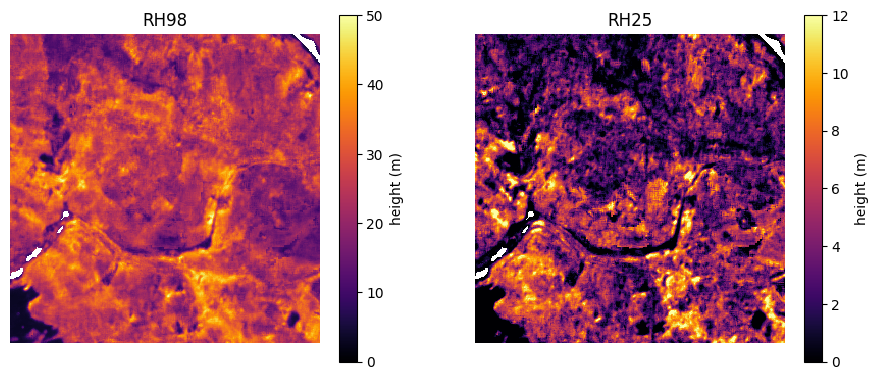

In [88]:
plot_maps(cube)

**The cube in 3D.** Each pixel in the data cube contains an RH profile: 101 height values, from RH0 to RH100. RHn is the height below which n% of the returned lidar energy has accumulated. Each successive RH metric marks a 1% increase in cumulative energy. Counting the RH1–RH100 values within each 1 m height bin therefore approximates the percentage of energy returned from that height interval.

Here, we visualise the original RH profile cube (rh × y × x) on the left, coloured by height, and the derived vertical profile cube (height × y × x) on the right, coloured by the share of returned energy in each bin. Empty bins are omitted, so the top of the visible cube follows the canopy.

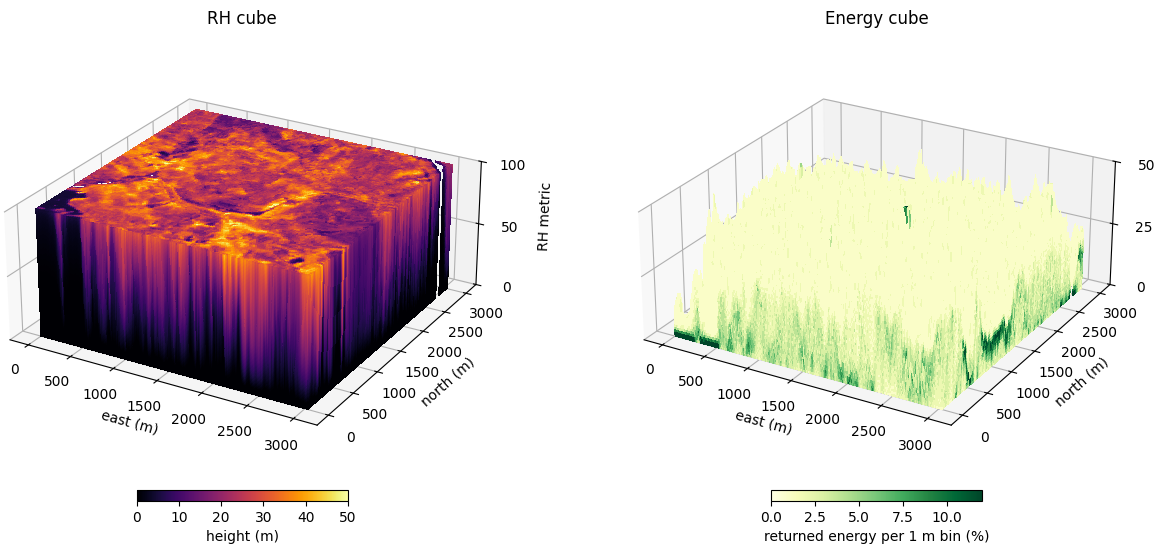

In [89]:
def to_vertical_profile(cube, top=50):
    """From the RH profile cube (rh, y, x) to the vertical profile cube (height, y, x).

    The vertical profile is the share of returned energy (%) in each 1 m height bin from 0 to `top` m.
    Each of RH1 ... RH100 holds 1 % of the returned energy, so the share of a bin is the number of RH metrics
    that fall in it. RH metrics at or below the ground are dropped; anything above `top` goes into the top bin.
    """
    h = cube.sel(rh=slice(1, 100)).values
    bins = np.minimum(np.floor(h), top - 1)
    share = np.stack([((bins == b) & (h > 0)).sum(axis=0) for b in range(top)]).astype("float32")
    share[:, np.isnan(h).all(axis=0)] = np.nan
    coords = {"height": np.arange(top) + 0.5, "y": cube.y, "x": cube.x}
    return xr.DataArray(share, coords=coords, dims=("height", "y", "x"), name="vertical_profile", attrs={"units": "%"})


vertical_profile_cube = to_vertical_profile(cube)
plot_cube_3d(cube, vertical_profile_cube)

For an interactive version, [open this location in the explorer](https://huizhml.github.io/vsm/explorer/?at=49.937,9.312#14.00/49.937/9.312): the link loads the 3D datacube of the 1.28 km window around the point, to rotate and cut open.

**A transect.** Taking a vertical slice through the vertical profile cube along a west–east line shows how vegetation structure varies across the landscape. The colours show the share of returned energy in each height bin, using the same scale as the side faces of the cube above.

Taking one pixel along the transect, we plot its RH profile alongside the vertical profile derived from it.

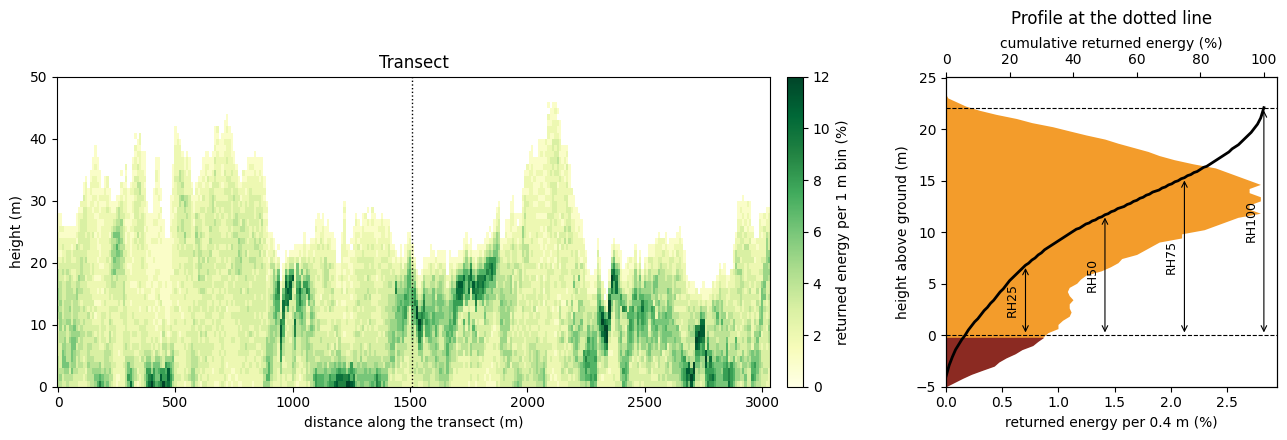

In [90]:
def vertical_profile(rh_heights, bin_size=0.4, bottom=-10, top=50):
    """From one pixel's RH profile (RH0 ... RH100, m) to its vertical profile: share of returned energy (%) per height bin.

    RH n is the height by which n % of the returned energy has accumulated, so the RH profile is a cumulative curve.
    Reading that curve at the bin edges and taking differences gives the share in each bin; a 5-bin
    moving average smooths it. The below-ground tail is kept.
    """
    edges = np.arange(bottom, top + bin_size / 2, bin_size)
    cumulative = np.interp(edges, np.maximum.accumulate(rh_heights), RHS)  # RH n never decreases with n
    share = np.convolve(np.diff(cumulative), np.ones(5) / 5, mode="same")
    return xr.DataArray(share, coords={"height": edges[:-1] + bin_size / 2}, dims="height", name="vertical_profile", attrs={"units": "%"})


# The cube is in UTM, so the point is transformed before it is looked up.
x0, y0 = Transformer.from_crs("EPSG:4326", cube.rio.crs, always_xy=True).transform(lon, lat)
transect = vertical_profile_cube.sel(y=y0, method="nearest")  # (height, x): the vertical profiles along one west-east line
pixel_rh = cube.sel(x=x0, y=y0, method="nearest")  # (rh): the RH profile of one pixel
pixel_profile = vertical_profile(pixel_rh.values)

plot_transect(transect, pixel_rh, pixel_profile)

## 2. Sample at points

Extract RH values at a set of locations specified by longitude and latitude.

Here, we define four example points directly, one in each of four vegetation types on four continents. To use your own locations, load a CSV file with lon and lat columns using pd.read_csv("my_plots.csv"). You can extract the full RH profile or select specific metrics with rhs, for example [25, 50, 75, 98].

A spatial join with the index gives the tile of every point. Points are then grouped by tile so that each tile is opened once and all points within it are sampled together.

In [91]:
points = pd.DataFrame(
    {
        "site": ["tropical rainforest", "temperate broadleaf forest", "boreal conifer forest", "savanna"],
        "lon": [117.7900, 9.3164, 24.2950, 31.4970],  # Borneo, Germany, Finland, South Africa
        "lat": [4.9600, 49.9370, 61.8470, -25.0200],
    }
)


def sample_points(points, rhs=RHS, year=YEAR):
    """RH metrics (m) at each point: the input table plus `tile` and one column per RH metric."""
    out = tile_of_points(points)
    values = []
    for tile, group in out.groupby("tile"):
        cube = open_tile(tile, rhs, year)
        x, y = Transformer.from_crs("EPSG:4326", cube.rio.crs, always_xy=True).transform(group.lon.values, group.lat.values)
        at_points = cube.sel(x=xr.DataArray(x, dims="point"), y=xr.DataArray(y, dims="point"), method="nearest")
        values.append(pd.DataFrame(at_points.values.T.astype(float).round(1), index=group.index, columns=[f"RH{rh}" for rh in rhs]))
    return out.join(pd.concat(values))


samples = sample_points(points)
samples[["site", "lon", "lat", "tile", "RH0", "RH25", "RH50", "RH75", "RH98", "RH100"]]

,site,lon,lat,tile,RH0,RH25,RH50,RH75,RH98,RH100
0,tropical rainforest,117.7900,4.960,50NNL,-4.5,11.3,21.3,30.8,43.3,45.4
1,temperate broadleaf forest,9.3164,49.937,32UNA,-4.2,9.5,15.3,18.8,22.9,24.5
2,boreal conifer forest,24.2950,61.847,34VFP,-4.9,-0.4,1.6,7.6,14.1,15.6
3,savanna,31.4970,-25.020,36JUT,-5.3,-1.1,0.1,1.3,4.1,5.7


A `NaN` row is a point on a nodata pixel (water, snow and ice, persistent cloud), or a point outside the tiles of the dataset.

Each row is the RH profile of one point. Plotted together, the four profiles show how the vertical structure differs between the vegetation types.

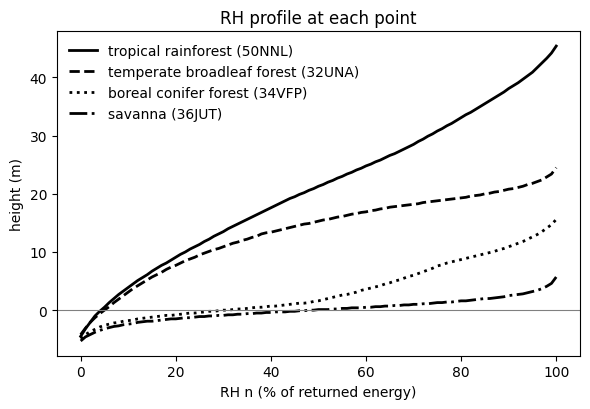

In [92]:
plot_samples(samples)

## 3. Sample patches

Instead of extracting one pixel per point, we now extract a 256 × 256 pixel patch (2.56 × 2.56 km) around each point, containing all 101 RH metrics. We also extract the corresponding patch from a Sentinel-2 image. These paired patches provide spectral and vertical structure information for the same area, ready for use in models that take image patches as input.

VSM uses the Sentinel-2 tiling and 10 m pixel grid, making it straightforward to find matching Sentinel-2 imagery and extract aligned patches. For each tile containing sample points, sample_patches:
1. Opens the VSM tile and searches the Earth Search STAC API for Sentinel-2 scenes with the same tile ID, selecting the scene from 2020 with the lowest reported cloud cover.
2. Checks that the VSM and Sentinel-2 data share the same pixel grid.
3. Extracts the same pixel window from both datasets around each point.
The tile ID can also help you find matching data from other products organised by Sentinel-2 tile. Before extracting paired patches, check that their CRS, resolution and pixel alignment match VSM. Data on a different grid, including Sentinel-2’s 20 m bands, need to be resampled to the VSM grid.

In [93]:
EARTH_SEARCH = "https://earth-search.aws.element84.com/v1"  # public STAC API with Sentinel-2 L2A as COGs


def find_sentinel2(tile, start, end):
    """The Sentinel-2 L2A scene of a tile with the least cloud and the fewest missing pixels in a period."""
    search = Client.open(EARTH_SEARCH).search(
        collections=["sentinel-2-l2a"], datetime=f"{start}/{end}", query={"grid:code": {"eq": f"MGRS-{tile}"}}
    )
    return min(search.items(), key=lambda item: item.properties["eo:cloud_cover"] + item.properties["s2:nodata_pixel_percentage"])


def open_sentinel2(scene, bands=("red", "green", "blue")):
    """One scene as a lazy (band, y, x) cube of surface reflectance, on the 10 m grid of its tile."""

    def open_band(name):
        asset = scene.assets[name]
        raster = asset.extra_fields["raster:bands"][0]  # scale and offset of the stored integers
        # Scenes processed since 2022 carry an offset of -0.1; where Earth Search has already
        # taken it out of the stored values (boa_offset_applied), it must not be added again.
        offset = 0 if scene.properties.get("earthsearch:boa_offset_applied") else raster["offset"]
        stored = rioxarray.open_rasterio(asset.href, chunks=1024, masked=True, lock=False).squeeze("band", drop=True)
        return stored * raster["scale"] + offset

    return xr.concat([open_band(b) for b in bands], dim=pd.Index(list(bands), name="band")).rename("reflectance")


def sample_patches(points, size=256, rhs=RHS, year=YEAR, period=("2020-01-01", "2020-12-31")):
    """A size x size pixel patch of VSM and of Sentinel-2 around each point: one Dataset with dims (point, rh | band, row, col)."""
    patches = []
    for tile, group in tile_of_points(points).groupby("tile"):
        # The same tile ID finds both products. They have the same CRS, the same 10 m resolution and
        # the same pixel grid, so their coordinates are identical: join="exact" raises an error if not.
        vsm = open_tile(tile, rhs, year)
        scene = find_sentinel2(tile, *period)
        vsm, s2 = xr.align(vsm, open_sentinel2(scene), join="exact")
        x, y = Transformer.from_crs("EPSG:4326", vsm.rio.crs, always_xy=True).transform(group.lon.values, group.lat.values)
        for point, px, py in zip(group.index, x, y):
            # Pixel window centred on the point, moved inwards where it would cross the tile edge.
            row = int(np.clip(abs(vsm.y - py).argmin() - size // 2, 0, vsm.sizes["y"] - size))
            col = int(np.clip(abs(vsm.x - px).argmin() - size // 2, 0, vsm.sizes["x"] - size))
            window = dict(y=slice(row, row + size), x=slice(col, col + size))
            patch = xr.Dataset({"height": vsm.isel(window), "reflectance": s2.isel(window)})
            # Patches of different tiles lie in different UTM zones: stack them on (row, col), each keeps its own x and y.
            patch = patch.drop_indexes(["y", "x"]).rename_dims(y="row", x="col").drop_vars("spatial_ref")
            patches.append(patch.assign_coords(point=point, tile=tile, crs=str(vsm.rio.crs), scene=scene.id))
    return xr.concat(patches, dim="point").sortby("point").compute()

In [94]:
patches = sample_patches(points)
patches

<xarray.Dataset> Size: 109MB
Dimensions:      (point: 4, rh: 101, row: 256, col: 256, band: 3)
Coordinates:
  * point        (point) int64 32B 0 1 2 3
    tile         (point) <U5 80B '50NNL' '32UNA' '34VFP' '36JUT'
    crs          (point) <U10 160B 'EPSG:32650' 'EPSG:32632' ... 'EPSG:32736'
    scene        (point) <U24 384B 'S2A_50NNL_20201106_0_L2A' ... 'S2B_36JUT_...
  * rh           (rh) int64 808B 0 1 2 3 4 5 6 7 8 ... 93 94 95 96 97 98 99 100
    y            (point, row) float64 8kB 5.496e+05 5.496e+05 ... 7.231e+06
    x            (point, col) float64 8kB 5.863e+05 5.863e+05 ... 3.496e+05
  * band         (band) object 24B 'red' 'green' 'blue'
Dimensions without coordinates: row, col
Data variables:
    height       (point, rh, row, col) float32 106MB -5.1 -4.7 -4.6 ... 9.4 8.5
    reflectance  (point, band, row, col) float32 3MB 0.0176 0.0167 ... 0.0898

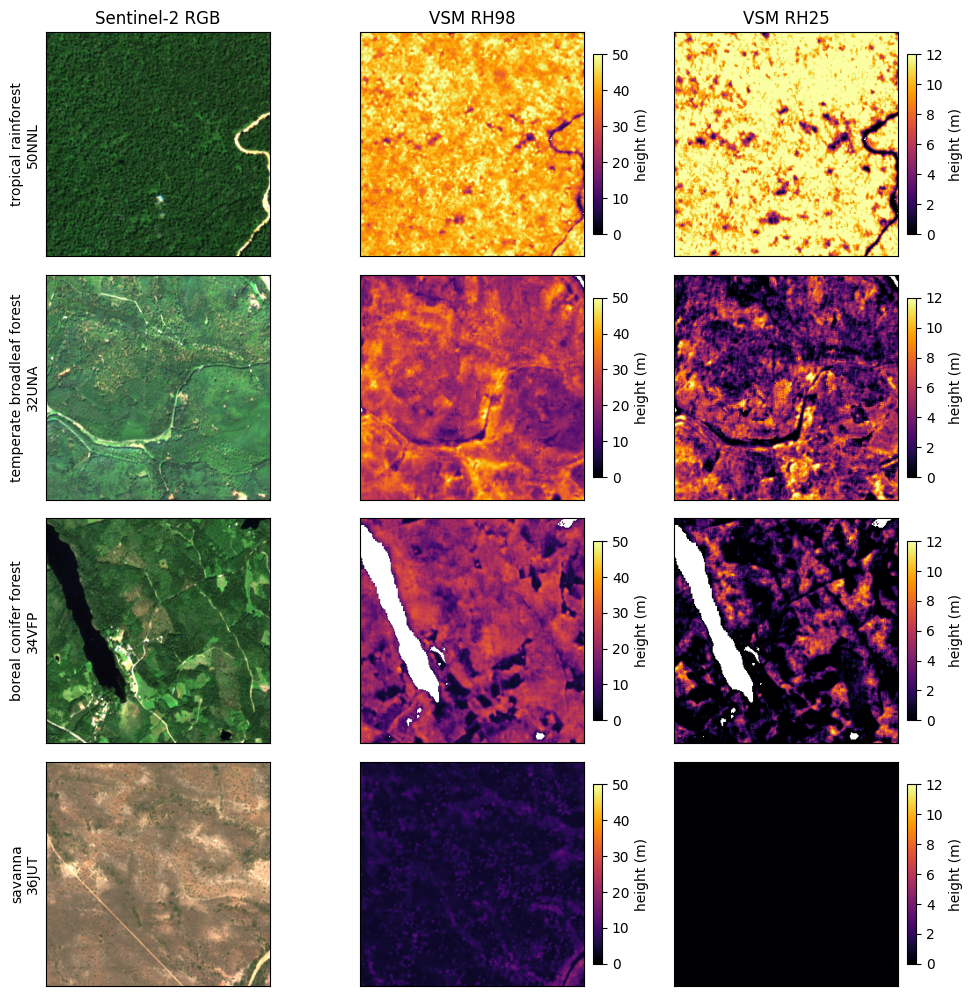

In [95]:
plot_patches(patches, points.site)

**Zonal statistics** are an optional next step on the extracted pixels. Here a zone is a patch; for your own zones (stands, protected areas), mask the pixels outside each polygon first.

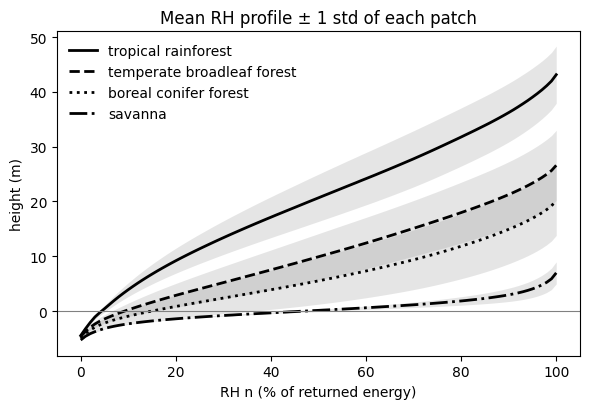

mean                    std               
rh                            25    50    75    98   25   50   75   98
site                                                                  
tropical rainforest         11.4  20.7  29.7  41.1  2.7  4.3  5.2  5.2
temperate broadleaf forest   4.0   9.9  16.5  25.0  2.6  4.2  5.3  6.4
boreal conifer forest        1.6   5.5  10.5  18.5  2.5  4.3  5.7  6.4
savanna                     -1.1   0.1   1.5   5.2  0.1  0.2  0.6  1.9

In [96]:
# Here a zone is a patch: mean and standard deviation of every RH metric over its pixels.
height = patches.height.assign_coords(point=points.site.values).rename(point="site")
stats = xr.Dataset({"mean": height.mean(("row", "col")), "std": height.std(("row", "col"))}).to_dataframe()[["mean", "std"]]
stats = stats.reorder_levels(["site", "rh"]).loc[points.site]  # one block of 101 rows per patch
plot_zonal_profiles(stats)
stats.unstack("rh").loc[points.site, (slice(None), [25, 50, 75, 98])].astype(float).round(1)

**Save** what the next step needs: the patches as Zarr (keeps the `point`, `rh` and `band` coordinates for `xarray`), the zonal statistics as a Parquet table, and the point samples as a CSV table.

In [97]:
patches.to_zarr("vsm_sentinel2_patches.zarr", mode="w")
stats.to_parquet("vsm_patch_stats.parquet")
samples.to_csv("vsm_point_samples.csv", index=False)

xr.open_zarr("vsm_sentinel2_patches.zarr")

<xarray.Dataset> Size: 109MB
Dimensions:      (point: 4, rh: 101, row: 256, col: 256, band: 3)
Coordinates:
  * point        (point) int64 32B 0 1 2 3
    crs          (point) <U10 160B dask.array<chunksize=(4,), meta=np.ndarray>
    scene        (point) <U24 384B dask.array<chunksize=(4,), meta=np.ndarray>
    tile         (point) <U5 80B dask.array<chunksize=(4,), meta=np.ndarray>
  * rh           (rh) int64 808B 0 1 2 3 4 5 6 7 8 ... 93 94 95 96 97 98 99 100
    y            (point, row) float64 8kB dask.array<chunksize=(4, 256), meta=np.ndarray>
    x            (point, col) float64 8kB dask.array<chunksize=(4, 256), meta=np.ndarray>
  * band         (band) object 24B 'red' 'green' 'blue'
Dimensions without coordinates: row, col
Data variables:
    height       (point, rh, row, col) float32 106MB dask.array<chunksize=(1, 26, 64, 128), meta=np.ndarray>
    reflectance  (point, band, row, col) float32 3MB dask.array<chunksize=(2, 2, 128, 256), meta=np.ndarray>

## More

- Want to download the whole tiles? the explorer's **Download data** panel writes a shell script that fetches them with `curl`, names each file and resumes broken transfers.
- For bulk access to the full dataset, contact huzh@di.ku.dk.
- Licence: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Please cite: Zhang, H., Lang, N., Mazurczyk, M., Oehmcke, S., Huang, K., Brandt, M., Fensholt, R., Kariryaa, A., & Igel, C. (2026). A vertical vegetation structure model of the Earth. *EarthArXiv preprint*. [doi:10.31223/X5M22F](https://doi.org/10.31223/X5M22F)